# 02 · EDA

Which customers leave? Contract, tenure, charges and services. Overall churn is 26.5%, so that's the line every group is compared against.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from churn.data import load

df = load()
overall = df["Churn"].mean()

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update(
    {
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)


def churn_rate(col):
    return df.groupby(col, observed=True)["Churn"].agg(rate="mean", customers="size")


def rate_bars(ax, rates, title):
    rates = rates.sort_values("rate")
    ax.barh(rates.index.astype(str), rates["rate"], color=BLUE, height=0.6)
    ax.axvline(overall, color=MUTED, ls="--", lw=1)
    for y, (r, n) in enumerate(zip(rates["rate"], rates["customers"], strict=True)):
        ax.text(
            r + 0.01,
            y,
            f"{r:.0%}  (n={n:,})",
            va="center",
            color=INK,
            fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1),
        )
    ax.set_xlim(0, 0.75)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(title, loc="left", color=INK)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)

## Contract, payment and internet type

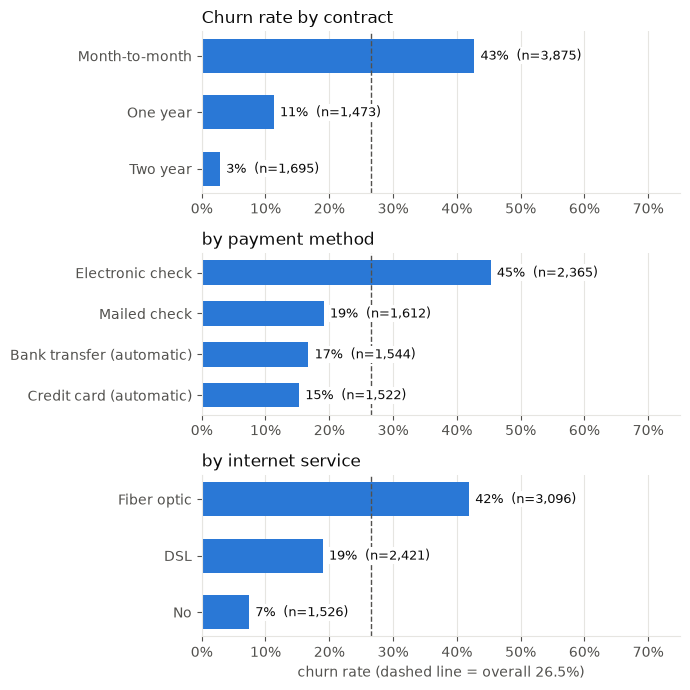

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(7, 7))
rate_bars(axes[0], churn_rate("Contract"), "Churn rate by contract")
rate_bars(axes[1], churn_rate("PaymentMethod"), "by payment method")
rate_bars(axes[2], churn_rate("InternetService"), "by internet service")
axes[2].set_xlabel("churn rate (dashed line = overall 26.5%)")
fig.tight_layout()
fig.savefig("../reports/figures/churn_by_contract_payment_internet.png", dpi=120)

- Month-to-month: **43%** churn. Two-year: **3%**. Contract is the biggest single split in the data.
- Electronic check: **45%**, every other payment method 15–19%. Automatic payments are "sticky".
- Fiber optic customers churn more than DSL (42% vs 19%) even though fiber is the better product. Price? Service quality? The data can't say.

## Is fiber just month-to-month in disguise?

Fiber customers could churn more simply because more of them are on monthly contracts. Checking both together:

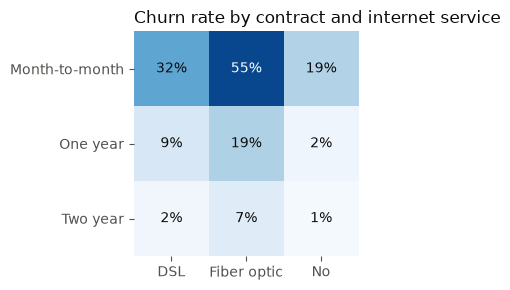

In [3]:
grid = pd.crosstab(df["Contract"], df["InternetService"], values=df["Churn"], aggfunc="mean")
fig, ax = plt.subplots(figsize=(6, 3))
im = ax.imshow(grid, cmap="Blues", vmin=0, vmax=0.6)
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.35 else INK)
ax.set_title("Churn rate by contract and internet service", loc="left", color=INK)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/contract_by_internet.png", dpi=120)

No. Within every contract type fiber still churns about 2–3× more than DSL (55% vs 32% on month-to-month). Both effects are real, and a month-to-month fiber customer is the riskiest profile: more than half leave.

## Tenure and charges

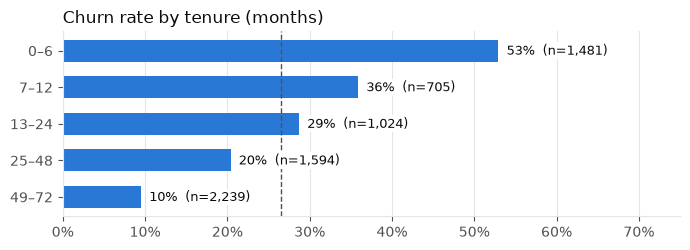

In [4]:
bands = pd.cut(
    df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0–6", "7–12", "13–24", "25–48", "49–72"]
)
fig, ax = plt.subplots(figsize=(7, 2.6))
rate_bars(
    ax,
    df.groupby(bands, observed=True)["Churn"].agg(rate="mean", customers="size"),
    "Churn rate by tenure (months)",
)
fig.tight_layout()
fig.savefig("../reports/figures/churn_by_tenure_band.png", dpi=120)

Sorting by rate also puts the tenure bands in order, because churn falls with every band. Dead end: I first tried a line plot per month (that's in 01), but it's noisy above 60 months where each month has few customers. The bands read more clearly.

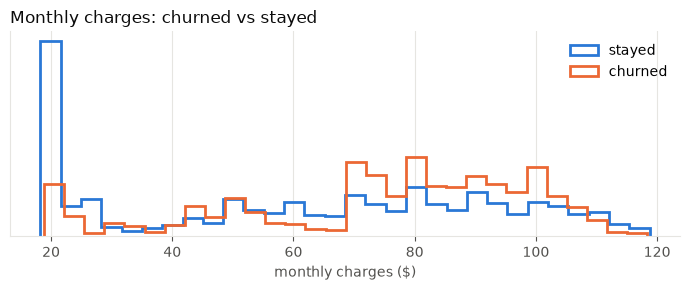

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
for label, color, name in [(0, BLUE, "stayed"), (1, ORANGE, "churned")]:
    ax.hist(
        df.loc[df["Churn"] == label, "MonthlyCharges"],
        bins=30,
        density=True,
        histtype="step",
        lw=2,
        color=color,
        label=name,
    )
ax.set(xlabel="monthly charges ($)", yticks=[])
ax.set_title("Monthly charges: churned vs stayed", loc="left", color=INK)
ax.legend(frameon=False)
ax.grid(axis="x", color=GRID, lw=0.8)
fig.tight_layout()
fig.savefig("../reports/figures/monthly_charges_by_churn.png", dpi=120)

In [6]:
churn_rate(pd.qcut(df["MonthlyCharges"], 4)).round(3)

,rate,customers
MonthlyCharges,,
"(18.249, 35.5]",0.112,1762
"(35.5, 70.35]",0.246,1766
"(70.35, 89.85]",0.375,1757
"(89.85, 118.75]",0.329,1758


Churners pile up at $70–105/month (mostly fiber). The cheapest quarter (under $35, mostly phone-only) churns at 11%. Note the top quarter (33%) churns a bit *less* than the third (38%), so this isn't a straight line, which a tree can capture and a plain logistic regression can't.

## Add-on services

,rate,customers
add-ons,,
0,0.567,1267
1,0.389,1467
2,0.238,1372
3,0.124,941
4,0.053,470


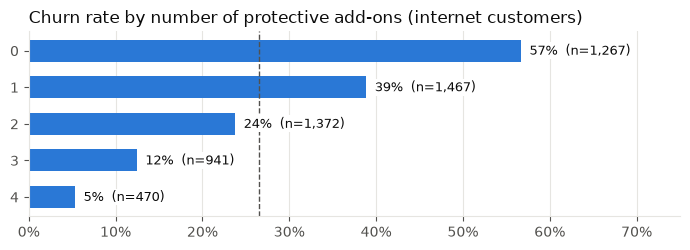

In [7]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
internet = df[df["InternetService"] != "No"]
n_addons = sum((internet[c] == "Yes").astype(int) for c in addons).rename("add-ons")
rates = internet.groupby(n_addons)["Churn"].agg(rate="mean", customers="size")
fig, ax = plt.subplots(figsize=(7, 2.6))
rate_bars(ax, rates, "Churn rate by number of protective add-ons (internet customers)")
fig.tight_layout()
fig.savefig("../reports/figures/churn_by_addons.png", dpi=120)
rates.round(3)

Each extra security/support add-on lowers churn: 57% with none, 5% with all four. Probably partly cause (support keeps people happy) and partly selection (committed customers buy more). Streaming add-ons barely move churn (30% vs 34%), so it's the *protective* services specifically.

## Barely matters

`gender` (27% vs 26%) and `PhoneService` (25% vs 27%) are flat. Expect them near zero in the models.

In [8]:
pd.concat({c: churn_rate(c)["rate"] for c in ["gender", "PhoneService", "StreamingTV"]}).round(3)

gender        Female                 0.269
              Male                   0.262
PhoneService  No                     0.249
              Yes                    0.267
StreamingTV   No                     0.335
              No internet service    0.074
              Yes                    0.301
Name: rate, dtype: float64

## Takeaways for modelling (Day 4+)

1. Contract, tenure, payment method and internet type carry most of the signal.
2. A count of protective add-ons looks like a useful engineered feature.
3. Charges are non-linear, worth comparing logistic regression with a tree.
4. Highest-risk profile: new, month-to-month, fiber, electronic check, no add-ons.